# Conteo de monedas y billetes colombianos

Un detector YOLO26 nano localiza cada moneda y cada billete, lee su denominación y suma el dinero de la escena.

Ejemplo: `Se detectaron 2 monedas de 100 y 1 billete de 2000. Total en escena: $2200`.


## 1. Datos

Las monedas están en el proyecto [monedas-v3](https://app.roboflow.com/pandebono-predictors-workspace/monedas-v3/3). Son las 2086 fotos del notebook de monedas. Dos traen la etiqueta girada y se excluyen (`data/etiquetas_giradas.csv`). Quedan 2084: 1251 de entrenamiento, 417 de validación y 416 de prueba. Cajas: `moneda_50` 737, `moneda_100` 792, `moneda_200` 742, `moneda_500` 636 y `moneda_1000` 632.

Los billetes están en [billetes colombianos](https://app.roboflow.com/pandebono-predictors-workspace/billetes-colombianos-lgn8w/1), versión best, sin aumentos. De las 5872 fotos con etiqueta se excluyen 51 con la etiqueta girada. Quedan 5821: 3499, 1159 y 1163. El reparto usa la semilla 42 sobre la lista completa y después quita esas fotos, así las demás no cambian de grupo. Cajas: `billete_2000` 897, `billete_5000` 1069, `billete_10000` 1057, `billete_20000` 846, `billete_50000` 1140 y `billete_100000` 904.

El conjunto unido queda en `data/monedas_billetes`: 4750 de entrenamiento, 1576 de validación y 1579 de prueba. Total 7905. Todas las etiquetas son cajas de cinco números. Al cargarlas no se descarta ninguna foto y no aparece el aviso de mezcla entre polígono y caja.

Hay además escenas sintéticas, armadas solo con recortes del mismo split: 1500, 300 y 300, en un lienzo de 1280x720. La mitad deja las piezas separadas y la mitad las superpone, dejando visible al menos el 55 % de cada una. No entran en la búsqueda de la sección 3. Entran en la sección 3b y en el entrenamiento final.

La búsqueda de hiperparámetros usa solo las fotos reales, 60/20/20. La sección 3b repite la receta ganadora y le añade las escenas. El último modelo ve fotos reales y sintéticas de todos los splits, y solo se usa en las fotos y los videos propios.


### Librerías

Imágenes, gráficas, tablas y YOLO. El registro largo de Ultralytics se apaga porque las curvas ya muestran el avance.


In [1]:
# 1. Importamos las librerías
import os
import statistics
from pathlib import Path

import cv2                       # leer imágenes y dibujar sobre ellas
import matplotlib.pyplot as plt  # mostrar imágenes y gráficas
import pandas as pd              # tablas con los resultados

# Ultralytics imprime miles de líneas de progreso mientras entrena; las curvas ya muestran ese avance
os.environ["YOLO_VERBOSE"] = "False"
from ultralytics import YOLO


### Rutas y clases

Dónde están los datos y los pesos, el umbral de confianza y el valor en pesos de cada clase.


In [2]:
# 2. Rutas del proyecto
ROOT = Path(r"C:\Users\Usuario\Documents\ICESI\Maestria Inteligencia Artificial aplicada\SEMESTRE 2\Proyecto II\3\taller")
DATA = ROOT / "data" / "monedas_billetes" / "data.yaml"       # monedas y billetes: carpetas y nombres de clase
PRETRAINED = ROOT.parent / "modelos" / "yolo" / "yolo26n.pt"  # YOLO26 nano preentrenado en COCO
RUN = ROOT / "modelo_extras"                                  # resultados de este notebook; el de monedas queda en modelo/
CONF = 0.40                                                   # confianza mínima: las cajas más débiles se ignoran

# 3. GPU NVIDIA. Si CUDA no está, paramos: entrenar en CPU tardaría muchas horas
import torch

if not torch.cuda.is_available():
    raise RuntimeError("No hay GPU CUDA. El entrenamiento no debe correr en CPU.")

DEVICE = 0  # nvidia-smi: índice 0 es la GeForce RTX 3070
torch.cuda.set_device(DEVICE)
print(torch.cuda.get_device_name(DEVICE))

# 4. Valor en pesos de cada clase (mismo orden que data.yaml: la clase 0 es moneda_50 y la 5 es billete_2000)
CLASS_VALUE = {
    "moneda_50": 50,
    "moneda_100": 100,
    "moneda_200": 200,
    "moneda_500": 500,
    "moneda_1000": 1000,
    "billete_2000": 2000,
    "billete_5000": 5000,
    "billete_10000": 10000,
    "billete_20000": 20000,
    "billete_50000": 50000,
    "billete_100000": 100000,
}
CLASS_NAMES = list(CLASS_VALUE)


NVIDIA GeForce RTX 3070


### Conteo

De las cajas al total en pesos y a la frase de la escena.


In [3]:
# 4. Funciones para contar monedas y billetes, y armar el mensaje final

# Suma el dinero: cada clase por el valor de esa clase
def total_pesos(conteos):
    return sum(CLASS_VALUE[nombre] * int(cantidad) for nombre, cantidad in conteos.items() if cantidad > 0)


# Separa el conteo en monedas o en billetes para leerlos aparte en las tablas
def parte(conteos, prefijo):
    return {nombre: int(cantidad) for nombre, cantidad in conteos.items() if nombre.startswith(prefijo)}


# Arma la frase "Se detectaron 2 monedas de 100 y 1 billete de 2000. Total en escena: $2200"
def texto_escena(conteos):
    partes = []
    for nombre in CLASS_NAMES:
        cantidad = int(conteos.get(nombre, 0))
        if cantidad <= 0:
            continue
        valor = CLASS_VALUE[nombre]
        if nombre.startswith("billete_"):
            unidad = "billete" if cantidad == 1 else "billetes"
        else:
            unidad = "moneda" if cantidad == 1 else "monedas"
        partes.append(f"{cantidad} {unidad} de {valor}")
    total = total_pesos(conteos)
    if not partes:
        return f"No se detectó dinero. Total en escena: ${total}"
    if len(partes) == 1:
        lista = partes[0]
    else:
        lista = ", ".join(partes[:-1]) + f" y {partes[-1]}"
    return f"Se detectaron {lista}. Total en escena: ${total}"


# Titulo de una linea para las figuras. El detalle queda en el texto impreso.
def titulo_corto(conteos):
    n_monedas = sum(int(conteos.get(nombre, 0)) for nombre in CLASS_NAMES if nombre.startswith("moneda_"))
    n_billetes = sum(int(conteos.get(nombre, 0)) for nombre in CLASS_NAMES if nombre.startswith("billete_"))
    monedas = "1 moneda" if n_monedas == 1 else f"{n_monedas} monedas"
    billetes = "1 billete" if n_billetes == 1 else f"{n_billetes} billetes"
    return f"{monedas}, {billetes}. Total ${total_pesos(conteos)}"


# Convierte una lista de nombres de clase en un diccionario {clase: cuántas}
def contar_nombres(nombres):
    conteos = {nombre: 0 for nombre in CLASS_NAMES}
    for nombre in nombres:
        if nombre in conteos:
            conteos[nombre] += 1
    return conteos


# Lee un archivo de etiquetas YOLO: una línea por pieza con "clase cx cy ancho alto"
def conteo_desde_etiqueta(texto):
    nombres = []
    for linea in texto.splitlines():
        if not linea.strip():
            continue
        class_id = int(float(linea.split()[0]))
        if 0 <= class_id < len(CLASS_NAMES):
            nombres.append(CLASS_NAMES[class_id])
    return contar_nombres(nombres)


# Lee la salida del modelo: boxes.cls trae el id de clase de cada caja detectada
def conteo_predicho(resultado):
    nombres = []
    if resultado.boxes is not None:
        for clase in resultado.boxes.cls.tolist():
            nombres.append(resultado.names[int(clase)])
    return contar_nombres(nombres)

def predecir_lotes(modelo, rutas, imgsz, lote=32):
    rutas = list(rutas)
    for inicio in range(0, len(rutas), lote):
        grupo = rutas[inicio:inicio + lote]
        for resultado in modelo.predict(
            [str(ruta) for ruta in grupo],
            conf=CONF,
            imgsz=imgsz,
            batch=16,
            device=DEVICE,
            stream=True,
            verbose=False,
        ):
            yield resultado


def filas_conteo(modelo, carpeta_imagenes, carpeta_etiquetas, imgsz):
    rutas = sorted(
        ruta for ruta in Path(carpeta_imagenes).iterdir()
        if ruta.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    )
    filas = []
    for ruta, resultado in zip(rutas, predecir_lotes(modelo, rutas, imgsz)):
        real = conteo_desde_etiqueta((Path(carpeta_etiquetas) / f"{ruta.stem}.txt").read_text(encoding="utf-8"))
        predicho = conteo_predicho(resultado)
        filas.append({
            "imagen": ruta.name,
            "real": total_pesos(real),
            "predicho": total_pesos(predicho),
            "real_monedas": total_pesos(parte(real, "moneda_")),
            "pred_monedas": total_pesos(parte(predicho, "moneda_")),
            "real_billetes": total_pesos(parte(real, "billete_")),
            "pred_billetes": total_pesos(parte(predicho, "billete_")),
            "coincide": real == predicho,
            "coincide_monedas": parte(real, "moneda_") == parte(predicho, "moneda_"),
            "coincide_billetes": parte(real, "billete_") == parte(predicho, "billete_"),
            "real_conteo": real,
            "pred_conteo": predicho,
        })
    return filas


## 2. Muestras etiquetadas

Tres fotos de entrenamiento que solo tienen monedas, y una foto de cada denominación de billete. Abajo, tres escenas sintéticas con la caja de lo que quedó visible.

Se excluyeron 53 fotos (51 billetes y 2 monedas) porque la etiqueta estaba girada 90° o 180° respecto a la imagen. El resto de las etiquetas de billete se guardó como el rectángulo que envuelve el contorno.


### Etiqueta a esquinas

Una moneda trae centro, ancho y alto. Un billete trae las esquinas del contorno. En los dos casos se dibuja el rectángulo en píxeles.


In [4]:
# 1. Rectángulo en píxeles. Moneda: centro y tamaño. Billete: el rectángulo que envuelve el contorno
def cajas_xyxy(texto, ancho, alto):
    cajas = []
    for linea in texto.splitlines():
        partes = linea.split()
        if len(partes) < 5:
            continue
        clase = int(float(partes[0]))
        numeros = [float(valor) for valor in partes[1:]]
        if len(numeros) == 4:
            cx, cy, w, h = numeros
            x1 = int((cx - w / 2) * ancho)
            y1 = int((cy - h / 2) * alto)
            x2 = int((cx + w / 2) * ancho)
            y2 = int((cy + h / 2) * alto)
        else:
            if len(numeros) % 2:
                numeros = numeros[:-1]
            xs = [valor * ancho for valor in numeros[0::2]]
            ys = [valor * alto for valor in numeros[1::2]]
            x1, y1, x2, y2 = int(min(xs)), int(min(ys)), int(max(xs)), int(max(ys))
        cajas.append((clase, x1, y1, x2, y2))
    return cajas


### Fotos reales y escenas sintéticas

Tres monedas, seis billetes (uno de cada valor) y tres escenas de `sint_train`.


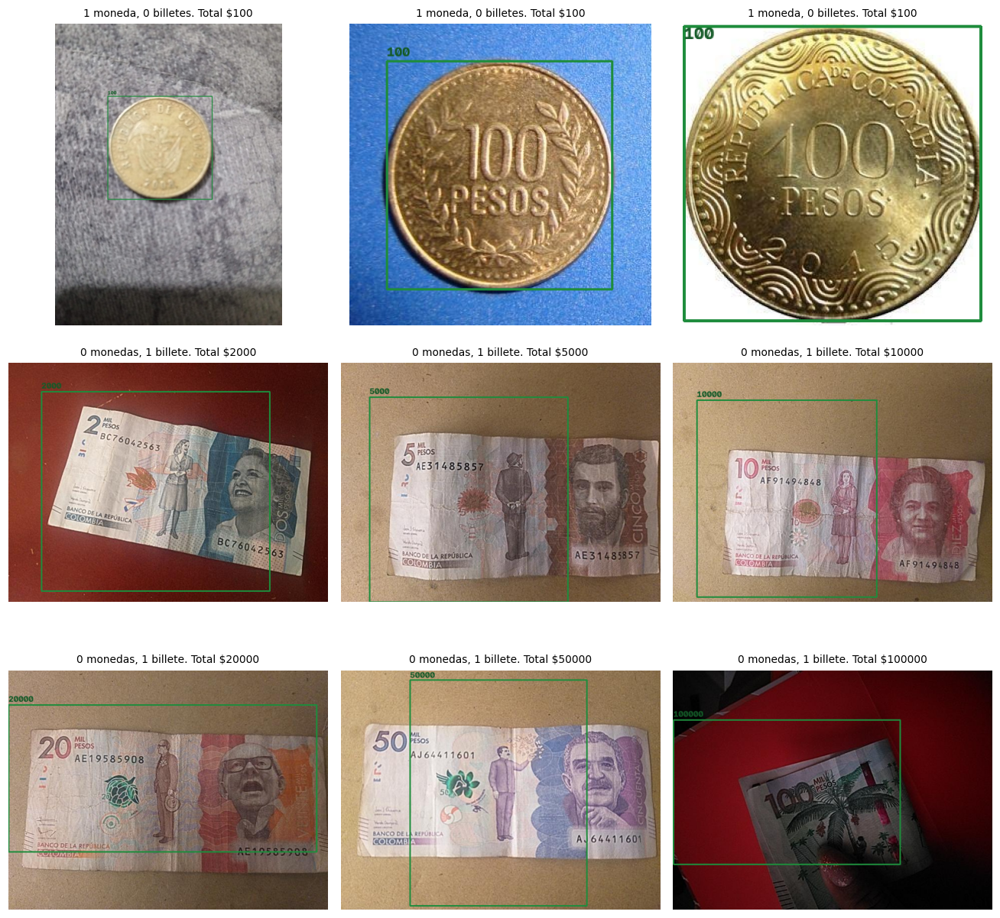

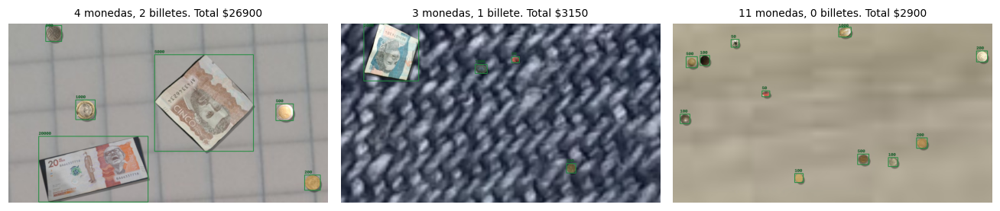

In [5]:
# 2. Tres monedas, un billete de cada denominacion y tres escenas sinteticas
train_dir = ROOT / "data" / "monedas_billetes" / "images" / "train"
label_dir = ROOT / "data" / "monedas_billetes" / "labels" / "train"
extensiones = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def ids_de(texto):
    return [int(float(linea.split()[0])) for linea in texto.splitlines() if linea.strip()]

solo_monedas = []
por_billete = {}
for imagen_path in sorted(train_dir.iterdir()):
    if imagen_path.suffix.lower() not in extensiones:
        continue
    texto = (label_dir / f"{imagen_path.stem}.txt").read_text(encoding="utf-8")
    ids = ids_de(texto)
    if not ids:
        continue
    if max(ids) <= 4 and len(solo_monedas) < 3:
        solo_monedas.append(imagen_path)
    if len(ids) == 1 and ids[0] >= 5 and ids[0] not in por_billete:
        por_billete[ids[0]] = imagen_path
faltan_clases = [clase for clase in range(5, 11) if clase not in por_billete]
if faltan_clases:
    raise RuntimeError(f"Falta una foto de estas clases de billete: {faltan_clases}")
muestras = solo_monedas + [por_billete[clase] for clase in range(5, 11)]


def mostrar_muestras(rutas, columnas, carpeta_etiquetas):
    filas_figura = (len(rutas) + columnas - 1) // columnas
    fig, ejes = plt.subplots(filas_figura, columnas, figsize=(4 * columnas, 3.8 * filas_figura))
    ejes_planos = list(ejes.ravel()) if filas_figura * columnas > 1 else [ejes]
    for eje in ejes_planos:
        eje.axis("off")
    for eje, imagen_path in zip(ejes_planos, rutas):
        imagen = cv2.cvtColor(cv2.imread(str(imagen_path)), cv2.COLOR_BGR2RGB)
        alto, ancho = imagen.shape[:2]
        texto = (carpeta_etiquetas / f"{imagen_path.stem}.txt").read_text(encoding="utf-8")
        for clase, x1, y1, x2, y2 in cajas_xyxy(texto, ancho, alto):
            cv2.rectangle(imagen, (x1, y1), (x2, y2), (30, 140, 60), 2)
            cv2.putText(
                imagen,
                str(CLASS_VALUE[CLASS_NAMES[clase]]),
                (x1, max(16, y1 - 6)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.55,
                (20, 90, 40),
                2,
                cv2.LINE_AA,
            )
        eje.imshow(imagen)
        eje.set_title(titulo_corto(conteo_desde_etiqueta(texto)), fontsize=9)
        eje.axis("off")
    fig.tight_layout()
    plt.show()
    plt.close(fig)


mostrar_muestras(muestras, 3, label_dir)
sint_dir = ROOT / "data" / "monedas_billetes" / "images" / "sint_train"
sint_lbl = ROOT / "data" / "monedas_billetes" / "labels" / "sint_train"
ejemplos_sint = sorted(sint_dir.glob("*.jpg"))[:3]
mostrar_muestras(ejemplos_sint, 3, sint_lbl)


## 3. Búsqueda de hiperparámetros

Las cuatro pruebas se entrenan con el 60 % de las fotos reales. La validación elige la mejor. El 20 % de prueba no entra en esa elección: queda para las secciones 5 a 9. Si `results.csv` y `best.pt` ya están en disco, la prueba no se vuelve a entrenar.

Cada prueba parte de `yolo26n.pt`. El tamaño queda en 640 y el lote en 16.

- **Tasa inicial (`lr0`): 0.005 o 0.01.** El optimizador queda en SGD. Con `optimizer=auto`, Ultralytics ignora `lr0`. `cos_lr=True` baja la tasa al final de las 50 épocas.
- **Peso de la clase (`cls`): 1.0 o 1.5.** Los errores que cambian el conteo son de denominación.
- **`copy_paste=0.1` no aporta en esta versión.** Ultralytics 8.4, cuando un dataset mezcla cajas y polígonos, vacía los segmentos y `CopyPaste` sale sin cambiar la foto. La sección 3b entrena sin `copy_paste`.
- **Lo demás queda fijo.** 50 épocas, paciencia de 15, semilla 42 y `cache=True`. Corren en la RTX 3070.

Se queda la prueba con mayor mAP50 de validación. Si dos quedan a menos de 0.01, se queda la de mayor recall. Ese modelo es el **A** de la comparación. Todavía no vio las escenas sintéticas, y se entrenó antes de quitar el 1 % de etiquetas giradas.


In [6]:
# 1. Cuatro pruebas: tasa inicial x peso de la clase
busqueda = [
    {"lr0": 0.005, "cls": 1.0},
    {"lr0": 0.005, "cls": 1.5},
    {"lr0": 0.01, "cls": 1.0},
    {"lr0": 0.01, "cls": 1.5},
]

filas_busqueda = []
for prueba in busqueda:
    nombre = f"lr{prueba['lr0']}_cls{prueba['cls']}"
    pesos_prueba = RUN / nombre / "weights" / "best.pt"
    curvas_prueba = RUN / nombre / "results.csv"
    if pesos_prueba.exists() and curvas_prueba.exists():
        print("Se reutiliza", nombre)
    else:
        modelo = YOLO(str(PRETRAINED))  # cada prueba vuelve a partir de los pesos de COCO
        modelo.train(
            data=str(DATA),          # 60 % entrenamiento, 20 % validación; la prueba no se usa aquí
            epochs=50,
            patience=15,             # corta si el mAP de validación no mejora en 15 épocas
            batch=16,
            imgsz=640,
            cls=prueba["cls"],       # peso de la pérdida de clase
            lr0=prueba["lr0"],
            optimizer="SGD",       # auto ignora lr0; SGD sí usa 0.005 y 0.01
            cos_lr=True,             # la tasa baja hacia el final, en lugar de quedar diminuta desde el inicio
            copy_paste=0.1,          # en 8.4 no cambia la foto si el conjunto mezcla cajas y poligonos
            cache=True,
            seed=42,
            workers=2,
            device=DEVICE,           # GPU NVIDIA (RTX 3070)
            project=str(RUN),
            name=nombre,
            exist_ok=True,
            plots=True,              # guarda las curvas y la matriz de confusión
        )
    curvas = pd.read_csv(RUN / nombre / "results.csv")
    curvas.columns = [columna.strip() for columna in curvas.columns]
    indice = curvas["metrics/mAP50(B)"].idxmax()
    fila = curvas.loc[indice]
    filas_busqueda.append({
        "prueba": nombre,
        "lr0": prueba["lr0"],
        "cls": prueba["cls"],
        "batch": 16,
        "imgsz": 640,
        "epoca": int(fila["epoch"]),
        "mAP50": float(fila["metrics/mAP50(B)"]),
        "mAP50-95": float(fila["metrics/mAP50-95(B)"]),
        "recall": float(fila["metrics/recall(B)"]),
    })

# 2. Elegimos por mAP50. Si dos quedan a menos de 0.01, gana el recall
tabla = pd.DataFrame(filas_busqueda)
print(tabla.sort_values(["mAP50", "recall"], ascending=False).rename(columns={"epoca": "época"}).to_string(index=False))
tope = tabla["mAP50"].max()
candidatos = tabla[tabla["mAP50"] >= tope - 0.01]
candidatos = candidatos.sort_values(["recall", "mAP50-95"], ascending=False)
ganador = candidatos.iloc[0]
carpeta = RUN / ganador["prueba"]
mejor = carpeta / "weights" / "best.pt"  # mejor época de validación; no vio las fotos de prueba
print("Prueba elegida:", ganador["prueba"], "| pesos:", mejor)


Se reutiliza lr0.005_cls1.0
Se reutiliza lr0.005_cls1.5
Se reutiliza lr0.01_cls1.0
Se reutiliza lr0.01_cls1.5
        prueba   lr0  cls  batch  imgsz  época   mAP50  mAP50-95  recall
lr0.005_cls1.0 0.005  1.0     16    640     36 0.94435   0.88637 0.89769
 lr0.01_cls1.5 0.010  1.5     16    640     36 0.94158   0.87642 0.89180
 lr0.01_cls1.0 0.010  1.0     16    640     39 0.94104   0.88523 0.90879
lr0.005_cls1.5 0.005  1.5     16    640     25 0.93675   0.86581 0.89916
Prueba elegida: lr0.01_cls1.0 | pesos: C:\Users\Usuario\Documents\ICESI\Maestria Inteligencia Artificial aplicada\SEMESTRE 2\Proyecto II\3\taller\modelo_extras\lr0.01_cls1.0\weights\best.pt


## 3b. Escenas sintéticas: antes y después

Se entrena otra vez la receta ganadora de la sección 3: `lr0=0.01`, `cls=1.0`, SGD, `cos_lr`, 50 épocas, tamaño 640 y lote 16, sin `copy_paste`. Lo único que cambia son los datos: entrena con `images/train` y `images/sint_train`, y valida con `images/val` y `images/sint_val`.

El modelo de la sección 3 es **A**. Este es **B**. Los dos se miden sobre los mismos splits ya limpios. A se entrenó antes de excluir las 53 etiquetas giradas; esa diferencia es cerca del 1 % de las fotos.

El tamaño de inferencia, 640 o 1280, se elige con el mAP50 de B en `sint_val`. Las ocho fotos propias solo se reportan: no eligen hiperparámetros ni tamaño.


In [7]:
# 1. Conteo real de las fotos propias, a mano. La 03 tiene monedas encimadas: se cuentan las que se ven.
def vacio():
    return {nombre: 0 for nombre in CLASS_NAMES}

def con_piezas(**cantidades):
    conteo = vacio()
    conteo.update(cantidades)
    return conteo

REAL_PROPIAS = {
    "foto_01_monedas_separadas.JPG": con_piezas(moneda_50=1, moneda_100=2, moneda_200=3, moneda_500=2, moneda_1000=1),
    "foto_02_monedas_con_contacto.JPG": con_piezas(moneda_50=1, moneda_100=5, moneda_200=5, moneda_500=4, moneda_1000=1),
    "foto_03_monedas_superpuestas.JPG": con_piezas(moneda_50=1, moneda_100=5, moneda_200=5, moneda_500=3, moneda_1000=1),
    "foto_04_billetes_separados.JPG": con_piezas(billete_2000=1, billete_5000=1, billete_20000=3, billete_50000=2, billete_100000=2),
    "foto_05_billetes_superpuestos.JPG": con_piezas(billete_2000=1, billete_5000=3, billete_10000=2, billete_20000=4, billete_50000=4, billete_100000=3),
    "foto_06_billetes_en_posiciones_variadas.JPG": con_piezas(billete_2000=1, billete_5000=3, billete_10000=2, billete_20000=4, billete_50000=4, billete_100000=3),
    "foto_07_monedas_y_billetes_organizados.JPG": con_piezas(moneda_100=3, moneda_200=4, moneda_500=3, billete_2000=2, billete_5000=1, billete_10000=1, billete_20000=3, billete_50000=1, billete_100000=1),
    "foto_08_monedas_y_billetes_con_superposicion.JPG": con_piezas(moneda_100=2, moneda_200=5, moneda_500=3, moneda_1000=1, billete_2000=2, billete_5000=1, billete_10000=2, billete_20000=2, billete_50000=1, billete_100000=2),
}
totales_billete = {
    "foto_04_billetes_separados.JPG": 367000,
    "foto_05_billetes_superpuestos.JPG": 617000,
    "foto_06_billetes_en_posiciones_variadas.JPG": 617000,
    "foto_07_monedas_y_billetes_organizados.JPG": 229000,
    "foto_08_monedas_y_billetes_con_superposicion.JPG": 319000,
}
for nombre_foto, total_billete in totales_billete.items():
    billetes = parte(REAL_PROPIAS[nombre_foto], "billete_")
    if total_pesos(billetes) != total_billete:
        raise RuntimeError(f"{nombre_foto} no suma {total_billete}")
mediciones = {}

# 2. YAML de B: fotos reales mas escenas del mismo split
datos = ROOT / "data" / "monedas_billetes"
nombres = list(CLASS_VALUE)

def escribir_yaml(ruta, train, val):
    lineas = ["path: " + datos.as_posix(), "train:"]
    for carpeta in train:
        lineas.append("  - " + carpeta)
    lineas.append("val: " + val)
    lineas.append("nc: " + str(len(nombres)))
    lineas.append("names: [" + ", ".join("'" + nombre + "'" for nombre in nombres) + "]")
    ruta.write_text("\n".join(lineas) + "\n", encoding="utf-8")

yaml_b = RUN / "data_b.yaml"
escribir_yaml(yaml_b, ["images/train", "images/sint_train"], "images/val")
yaml_val = RUN / "data_val_real.yaml"
escribir_yaml(yaml_val, ["images/train"], "images/val")
yaml_sint_val = RUN / "data_sint_val.yaml"
escribir_yaml(yaml_sint_val, ["images/sint_train"], "images/sint_val")
# La validacion de B mezcla fotos reales y escenas. El yaml de entrenamiento lleva las dos.
yaml_b_train = RUN / "data_b_train.yaml"
lineas_val = ["path: " + datos.as_posix(), "train:", "  - images/train", "  - images/sint_train", "val:", "  - images/val", "  - images/sint_val"]
lineas_val.append("nc: " + str(len(nombres)))
lineas_val.append("names: [" + ", ".join("'" + nombre + "'" for nombre in nombres) + "]")
yaml_b_train.write_text("\n".join(lineas_val) + "\n", encoding="utf-8")

# 3. Misma receta que A, sin copy_paste, con las escenas
pesos_a = RUN / "lr0.01_cls1.0" / "weights" / "best.pt"
pesos_b = RUN / "receta_b" / "weights" / "best.pt"
if not pesos_a.exists():
    raise RuntimeError("Falta el modelo A de la seccion 3.")
if pesos_b.exists() and (RUN / "receta_b" / "results.csv").exists():
    print("Se reutiliza receta_b")
else:
    modelo_b = YOLO(str(PRETRAINED))
    modelo_b.train(
        data=str(yaml_b_train),
        epochs=50,
        patience=50,
        batch=16,
        imgsz=640,
        cls=1.0,
        lr0=0.01,
        optimizer="SGD",
        cos_lr=True,
        cache=True,
        seed=42,
        workers=2,
        device=DEVICE,
        project=str(RUN),
        name="receta_b",
        exist_ok=True,
        plots=True,
    )

def mapa50(pesos, yaml_ruta, imgsz, nombre):
    modelo = YOLO(str(pesos))
    metricas = modelo.val(
        data=str(yaml_ruta),
        split="val",
        imgsz=imgsz,
        batch=8 if imgsz > 640 else 16,
        device=DEVICE,
        plots=False,
        verbose=False,
        workers=2,
        project=str(RUN),
        name=nombre,
        exist_ok=True,
    )
    if hasattr(metricas, "box"):
        return float(metricas.box.map50)
    return float(metricas.results_dict["metrics/mAP50(B)"])

mapa_a_val = mapa50(pesos_a, yaml_val, 640, "val_a_real")
mapa_b_val = mapa50(pesos_b, yaml_val, 640, "val_b_real")
mapa_a_sint = mapa50(pesos_a, yaml_sint_val, 640, "val_a_sint")
mapa_b_sint = mapa50(pesos_b, yaml_sint_val, 640, "val_b_sint640")
mapa_b_sint_1280 = mapa50(pesos_b, yaml_sint_val, 1280, "val_b_sint1280")
IMGSZ = 1280 if mapa_b_sint_1280 > mapa_b_sint else 640
print(f"mAP50 sint_val de B: 640 -> {mapa_b_sint:.3f} | 1280 -> {mapa_b_sint_1280:.3f} | se usa {IMGSZ}")

# 4. Acierto de conteo en la prueba real y en las escenas de prueba
modelo_a = YOLO(str(pesos_a))
modelo_b = YOLO(str(pesos_b))
test_dir = ROOT / "data" / "monedas_billetes" / "images" / "test"
test_labels = ROOT / "data" / "monedas_billetes" / "labels" / "test"
sint_test_dir = ROOT / "data" / "monedas_billetes" / "images" / "sint_test"
sint_test_labels = ROOT / "data" / "monedas_billetes" / "labels" / "sint_test"
filas_a_test = filas_conteo(modelo_a, test_dir, test_labels, IMGSZ)
filas_b_test = filas_conteo(modelo_b, test_dir, test_labels, IMGSZ)
filas_a_sint = filas_conteo(modelo_a, sint_test_dir, sint_test_labels, IMGSZ)
filas_b_sint = filas_conteo(modelo_b, sint_test_dir, sint_test_labels, IMGSZ)

def media_coincide(filas):
    return sum(fila["coincide"] for fila in filas) / len(filas)

comparacion = pd.DataFrame([
    {
        "modelo": "A",
        "mAP50 val real": round(mapa_a_val, 4),
        "mAP50 sint_val": round(mapa_a_sint, 4),
        "conteo test": round(media_coincide(filas_a_test), 4),
        "conteo sint_test": round(media_coincide(filas_a_sint), 4),
    },
    {
        "modelo": "B",
        "mAP50 val real": round(mapa_b_val, 4),
        "mAP50 sint_val": round(mapa_b_sint, 4),
        "conteo test": round(media_coincide(filas_b_test), 4),
        "conteo sint_test": round(media_coincide(filas_b_sint), 4),
    },
])
print(comparacion.to_string(index=False))
print(f"imgsz de inferencia: {IMGSZ}")

# 5. Fotos propias: solo reporte, no decide el modelo
propias_dir = ROOT / "fotos_propias"
nombres_propias = list(REAL_PROPIAS)
print("Billetes en fotos propias (real | A | B), a modo de reporte:")
for nombre_foto in nombres_propias:
    ruta = propias_dir / nombre_foto
    real_b = sum(parte(REAL_PROPIAS[nombre_foto], "billete_").values())
    pred_a = conteo_predicho(modelo_a.predict(str(ruta), conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0])
    pred_b = conteo_predicho(modelo_b.predict(str(ruta), conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0])
    print(f"  {nombre_foto}: real {real_b} | A {sum(parte(pred_a, 'billete_').values())} | B {sum(parte(pred_b, 'billete_').values())}")

if media_coincide(filas_b_sint) <= media_coincide(filas_a_sint):
    raise RuntimeError("B no mejora el conteo en sint_test. Hay que corregir las escenas antes de seguir.")
if mapa_b_val < mapa_a_val - 0.02:
    raise RuntimeError("B pierde mas de 0.02 de mAP50 en la validacion real.")

mediciones["comparacion"] = comparacion
mediciones["imgsz"] = IMGSZ
carpeta = RUN / "receta_b"
mejor = carpeta / "weights" / "best.pt"
print("Modelo de aqui en adelante:", mejor)


mAP50 sint_val de B: 640 -> 0.960 | 1280 -> 0.945 | se usa 640


modelo  mAP50 val real  mAP50 sint_val  conteo test  conteo sint_test
     A          0.9417          0.3104       0.9455            0.0067
     B          0.9258          0.9602       0.9405            0.6100
imgsz de inferencia: 640
Billetes en fotos propias (real | A | B), a modo de reporte:
  foto_01_monedas_separadas.JPG: real 0 | A 0 | B 0


  foto_02_monedas_con_contacto.JPG: real 0 | A 0 | B 0
  foto_03_monedas_superpuestas.JPG: real 0 | A 0 | B 0
  foto_04_billetes_separados.JPG: real 9 | A 1 | B 9


  foto_05_billetes_superpuestos.JPG: real 17 | A 0 | B 12
  foto_06_billetes_en_posiciones_variadas.JPG: real 17 | A 0 | B 16
  foto_07_monedas_y_billetes_organizados.JPG: real 9 | A 0 | B 9


  foto_08_monedas_y_billetes_con_superposicion.JPG: real 10 | A 2 | B 10
Modelo de aqui en adelante: C:\Users\Usuario\Documents\ICESI\Maestria Inteligencia Artificial aplicada\SEMESTRE 2\Proyecto II\3\taller\modelo_extras\receta_b\weights\best.pt


## 4. Curvas

Las curvas son las del modelo B, el de la sección 3b. La pérdida de caja dice si encontró la pieza. La pérdida de clase dice si le atinó a la denominación. El mAP50 mezcla las dos.

La celda imprime la mejor época, el salto de la época 41 (ahí se apaga el mosaico) y la brecha final entre la pérdida de clase de validación y la de entrenamiento.


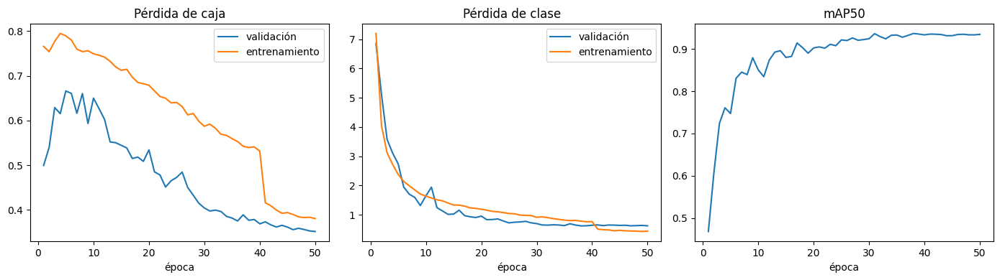

Mejor mAP50: 0.937 en la época 38 | última época: 50
Pérdida de clase al final: entrenamiento 0.441 | validación 0.623 | brecha 0.182
Época 40: clase entrenamiento 0.765 | clase validación 0.643 | mAP50 0.934
Época 41: clase entrenamiento 0.512 | clase validación 0.655 | mAP50 0.935
En la época 41 Ultralytics apaga el mosaico (close_mosaic=10 en 50 épocas). El cambio entre la época 40 y la 41 viene de eso. La brecha de la pérdida de clase es cuánto peor clasifica la validación que el entrenamiento al final.


In [8]:
# 1. Ultralytics guarda las métricas de cada época en results.csv
curvas = pd.read_csv(carpeta / "results.csv")
curvas.columns = [columna.strip() for columna in curvas.columns]

# 2. Caja, clase y mAP50. La del centro es la de la denominación
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
ejes[0].plot(curvas["epoch"], curvas["val/box_loss"], label="validación")
ejes[0].plot(curvas["epoch"], curvas["train/box_loss"], label="entrenamiento")
ejes[0].set_title("Pérdida de caja")
ejes[0].set_xlabel("época")
ejes[0].legend()
ejes[1].plot(curvas["epoch"], curvas["val/cls_loss"], label="validación")
ejes[1].plot(curvas["epoch"], curvas["train/cls_loss"], label="entrenamiento")
ejes[1].set_title("Pérdida de clase")
ejes[1].set_xlabel("época")
ejes[1].legend()
ejes[2].plot(curvas["epoch"], curvas["metrics/mAP50(B)"])
ejes[2].set_title("mAP50")
ejes[2].set_xlabel("época")
fig.tight_layout()
plt.show()

# 3. Mejor epoca, el salto al cerrar el mosaico y la brecha de la clase
indice_mejor = curvas["metrics/mAP50(B)"].idxmax()
epoca_mejor = int(curvas.loc[indice_mejor, "epoch"])
mapa_mejor = float(curvas.loc[indice_mejor, "metrics/mAP50(B)"])

def metrica_epoca(epoca, columna):
    sub = curvas.loc[curvas["epoch"] == epoca]
    if sub.empty:
        return None
    return float(sub.iloc[0][columna])

def texto_num(valor):
    return "n/a" if valor is None else f"{valor:.3f}"

cls_train = float(curvas["train/cls_loss"].iloc[-1])
cls_val = float(curvas["val/cls_loss"].iloc[-1])
print(f"Mejor mAP50: {mapa_mejor:.3f} en la época {epoca_mejor} | última época: {int(curvas['epoch'].iloc[-1])}")
print(f"Pérdida de clase al final: entrenamiento {cls_train:.3f} | validación {cls_val:.3f} | brecha {cls_val - cls_train:.3f}")
for epoca in (40, 41):
    print(
        f"Época {epoca}: clase entrenamiento {texto_num(metrica_epoca(epoca, 'train/cls_loss'))} | "
        f"clase validación {texto_num(metrica_epoca(epoca, 'val/cls_loss'))} | "
        f"mAP50 {texto_num(metrica_epoca(epoca, 'metrics/mAP50(B)'))}"
    )
print(
    "En la época 41 Ultralytics apaga el mosaico (close_mosaic=10 en 50 épocas). "
    "El cambio entre la época 40 y la 41 viene de eso. "
    "La brecha de la pérdida de clase es cuánto peor clasifica la validación que el entrenamiento al final."
)
mediciones["curvas"] = {
    "epoca_mejor": epoca_mejor,
    "mapa_mejor": mapa_mejor,
    "cls_train": cls_train,
    "cls_val": cls_val,
    "brecha": cls_val - cls_train,
    "m40": metrica_epoca(40, "metrics/mAP50(B)"),
    "m41": metrica_epoca(41, "metrics/mAP50(B)"),
    "cls40": metrica_epoca(40, "train/cls_loss"),
    "cls41": metrica_epoca(41, "train/cls_loss"),
}


**Lectura de las curvas.** Los números los imprime la celda anterior: mejor época, épocas 40 y 41, y brecha de la pérdida de clase.


## 5. Inferencia y suma

Se usa el modelo B de la sección 3b. Se toma una foto de la prueba real que ese modelo no usó para elegir hiperparámetros. Primero se elige una donde el conteo coincide, prefiriendo la de más piezas. Después se muestran la clase, la confianza, la suma y la frase.

El tamaño de la inferencia es el que salió de `sint_val` en la sección 3b.


### Foto de prueba

Se elige una foto de prueba en la que la predicción coincide con las etiquetas, prefiriendo la de más piezas.


In [9]:
# 1. Modelo B. Elegimos una foto de prueba donde la prediccion coincide, prefiriendo la de mas piezas
detector = YOLO(str(mejor))
test_dir = ROOT / "data" / "monedas_billetes" / "images" / "test"
test_labels = ROOT / "data" / "monedas_billetes" / "labels" / "test"
rutas_test = sorted(ruta for ruta in test_dir.iterdir() if ruta.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"})
imagen_demo = None
conteo = None
for ruta, resultado in zip(rutas_test, predecir_lotes(detector, rutas_test, IMGSZ)):
    real = conteo_desde_etiqueta((test_labels / f"{ruta.stem}.txt").read_text(encoding="utf-8"))
    if sum(real.values()) < 1:
        continue
    predicho = conteo_predicho(resultado)
    if predicho == real and (imagen_demo is None or sum(real.values()) > sum(conteo.values())):
        imagen_demo = ruta
        conteo = predicho
if imagen_demo is None:
    imagen_demo = rutas_test[0]
    conteo = conteo_desde_etiqueta((test_labels / f"{imagen_demo.stem}.txt").read_text(encoding="utf-8"))
    print("Ninguna foto coincidió por completo. Se muestra", imagen_demo.name)
else:
    print("Foto de ejemplo:", imagen_demo.name)


Foto de ejemplo: 1699630493540_2XxoP4Ni2a8YE6zgVCBa.jpg


### Cajas, suma y frase

Clase y confianza de cada caja, la suma en pesos y el mensaje final.


          clase  confianza  valor
0     moneda_50       0.97     50
1     moneda_50       0.97     50
2     moneda_50       0.97     50
3     moneda_50       0.96     50
4     moneda_50       0.95     50
5     moneda_50       0.95     50
6     moneda_50       0.94     50
7     moneda_50       0.94     50
8     moneda_50       0.90     50
9     moneda_50       0.58     50
10  moneda_1000       0.49   1000

Suma de los valores: 1500
Se detectaron 10 monedas de 50 y 1 moneda de 1000. Total en escena: $1500


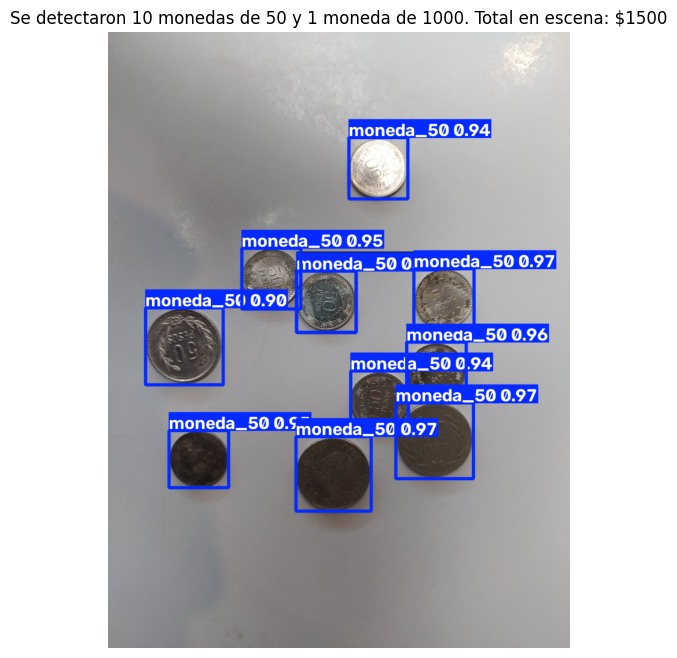

In [10]:
# 3. Corremos el modelo sobre la foto elegida; [0] es el resultado de esa única imagen
resultado = detector.predict(str(imagen_demo), conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]

# 4. Leemos los tensores de salida: boxes.cls trae la clase de cada caja y boxes.conf su confianza
detecciones = []
for clase, confianza in zip(resultado.boxes.cls.tolist(), resultado.boxes.conf.tolist()):
    nombre = resultado.names[int(clase)]  # id de clase -> nombre, por ejemplo 3 -> "moneda_500"
    detecciones.append({"clase": nombre, "confianza": round(confianza, 2), "valor": CLASS_VALUE[nombre]})
print(pd.DataFrame(detecciones))
print()

# 5. Sumamos los valores y armamos el mensaje final
print("Suma de los valores:", sum(fila["valor"] for fila in detecciones))
print(texto_escena(conteo_predicho(resultado)))

# 6. Mostramos la foto con las cajas; plot() las dibuja en BGR, así que se convierte a RGB
anotada = cv2.cvtColor(resultado.plot(), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 8))
plt.imshow(anotada)
plt.axis("off")
plt.title(texto_escena(conteo_predicho(resultado)))
plt.show()


## 6. Validación del conteo

En cada foto se compara el conteo de la predicción con el de las etiquetas. El umbral es 0.40 y el tamaño es el que eligió la sección 3b.

El acierto de monedas se calcula solo sobre las fotos que tienen monedas. El de billetes, solo sobre las que tienen billetes. Contar un 0 = 0 en una foto que no trae ese tipo inflaba el porcentaje. Lo mismo se reporta en `sint_test`.


In [11]:
# 1. Conteo en la prueba real y en las escenas de prueba, con el modelo B
filas = filas_conteo(detector, test_dir, test_labels, IMGSZ)
filas_sint = filas_conteo(
    detector,
    ROOT / "data" / "monedas_billetes" / "images" / "sint_test",
    ROOT / "data" / "monedas_billetes" / "labels" / "sint_test",
    IMGSZ,
)

def informar_conteo(filas_local, titulo):
    frame = pd.DataFrame(filas_local)
    con_monedas = frame[frame["real_monedas"] > 0]
    con_billetes = frame[frame["real_billetes"] > 0]
    print(titulo)
    print(f"Fotos: {len(frame)}")
    print(f"Acierto del total en pesos: {(frame['real'] == frame['predicho']).mean():.1%}")
    print(f"Acierto del conteo por denominación: {frame['coincide'].mean():.1%}")
    print(f"Monedas, solo fotos con monedas: {con_monedas['coincide_monedas'].mean():.1%} ({len(con_monedas)} fotos)")
    print(f"Billetes, solo fotos con billetes: {con_billetes['coincide_billetes'].mean():.1%} ({len(con_billetes)} fotos)")
    print()
    return frame

tabla = informar_conteo(filas, "Prueba real")
tabla_sint = informar_conteo(filas_sint, "Escenas sintéticas de prueba")
tabla[["imagen", "real", "predicho", "real_monedas", "pred_monedas", "real_billetes", "pred_billetes", "coincide"]]


Prueba real
Fotos: 1579
Acierto del total en pesos: 94.0%
Acierto del conteo por denominación: 94.0%
Monedas, solo fotos con monedas: 82.9% (416 fotos)
Billetes, solo fotos con billetes: 98.1% (1163 fotos)

Escenas sintéticas de prueba
Fotos: 300
Acierto del total en pesos: 61.7%
Acierto del conteo por denominación: 61.0%
Monedas, solo fotos con monedas: 58.2% (182 fotos)
Billetes, solo fotos con billetes: 82.4% (272 fotos)



,imagen,real,predicho,real_monedas,pred_monedas,real_billetes,pred_billetes,coincide
0,1373-original_9xQkLDGlesiAgUJV8PtM.jpg,50,200,50,200,0,0,False
1,1699630491435_26ydOioLd0fENPm36Nol.jpg,2000,0,2000,0,0,0,False
2,1699630491936_0t3p4AzJJ0qahEI3dLXK.jpg,9000,13000,9000,13000,0,0,False
3,1699630492542_FnaaW5G2spOslqrcvDCz.jpg,200,200,200,200,0,0,True
4,1699630493204_DtxYzNH7EKTU7vlLLYjf.jpg,150,150,150,150,0,0,True
...,...,...,...,...,...,...,...,...
1574,WhatsApp-Image-2023-11-22-at-3-18-46-PM_94jadm...,100,100,100,100,0,0,True
1575,WhatsApp-Image-2023-11-22-at-3-22-29-PM_E41uyW...,500,500,500,500,0,0,True
1576,WhatsApp-Image-2023-11-22-at-3-22-30-PM-1-_22j...,500,500,500,500,0,0,True
1577,WhatsApp-Image-2023-11-22-at-3-22-36-PM_3cCGuQ...,500,500,500,500,0,0,True


## 7. Falsos positivos y falsos negativos

Un falso positivo es una denominación de más. Un falso negativo es una denominación que faltó. Abajo, hasta 4 fotos donde el total no coincide.


### De más y de menos

Cuenta las denominaciones que sobran y las que faltan.


In [12]:
from collections import Counter

# 1. Comparamos clase por clase: más predichas que reales es un falso positivo, menos es un falso negativo
falsos_positivos = Counter()
falsos_negativos = Counter()
for fila in filas:
    for nombre in CLASS_NAMES:
        delta = fila["pred_conteo"][nombre] - fila["real_conteo"][nombre]
        if delta > 0:
            falsos_positivos[nombre] += delta
        elif delta < 0:
            falsos_negativos[nombre] += -delta

print("Falsos positivos, monedas:", {k: v for k, v in falsos_positivos.items() if k.startswith("moneda_")})
print("Falsos positivos, billetes:", {k: v for k, v in falsos_positivos.items() if k.startswith("billete_")})
print("Falsos negativos, monedas:", {k: v for k, v in falsos_negativos.items() if k.startswith("moneda_")})
print("Falsos negativos, billetes:", {k: v for k, v in falsos_negativos.items() if k.startswith("billete_")})


Falsos positivos, monedas: {'moneda_200': 40, 'moneda_1000': 12, 'moneda_500': 10, 'moneda_100': 21, 'moneda_50': 5}
Falsos positivos, billetes: {'billete_100000': 4, 'billete_5000': 2, 'billete_50000': 1}
Falsos negativos, monedas: {'moneda_50': 27, 'moneda_1000': 6, 'moneda_200': 10, 'moneda_100': 9}
Falsos negativos, billetes: {'billete_2000': 7, 'billete_5000': 4, 'billete_10000': 1, 'billete_50000': 2, 'billete_100000': 1, 'billete_20000': 2}


### Hasta cuatro fotos

Fotos de prueba en las que el total en pesos no coincide.


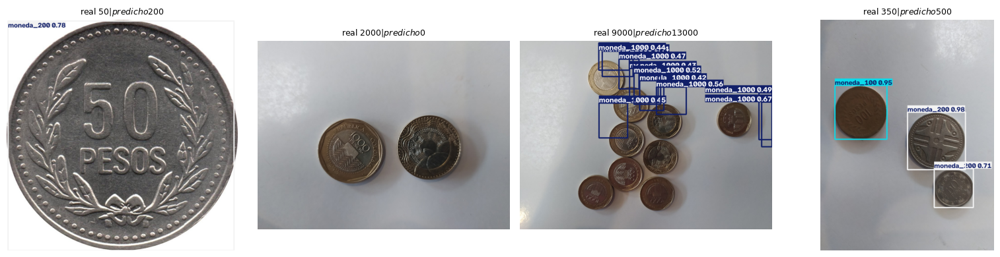

In [13]:
# 2. Mostramos hasta 4 fotos donde el total en pesos quedó mal
fallos = [fila for fila in filas if fila["real"] != fila["predicho"]][:4]
if not fallos:
    print("En la prueba, el total en pesos coincidió en todas las fotos.")
else:
    fig, ejes = plt.subplots(1, len(fallos), figsize=(4 * len(fallos), 4))
    if len(fallos) == 1:
        ejes = [ejes]
    for eje, fila in zip(ejes, fallos):
        resultado = detector.predict(str(test_dir / fila["imagen"]), conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        imagen = cv2.cvtColor(resultado.plot(), cv2.COLOR_BGR2RGB)
        eje.imshow(imagen)
        eje.axis("off")
        eje.set_title(f"real ${fila['real']} | predicho ${fila['predicho']}", fontsize=9)
    fig.tight_layout()
    plt.show()


La matriz de confusión la genera Ultralytics sobre la validación. Cada fila es la clase predicha y cada columna la clase real; `background` es una pieza que no se detectó o una detección donde no había dinero.


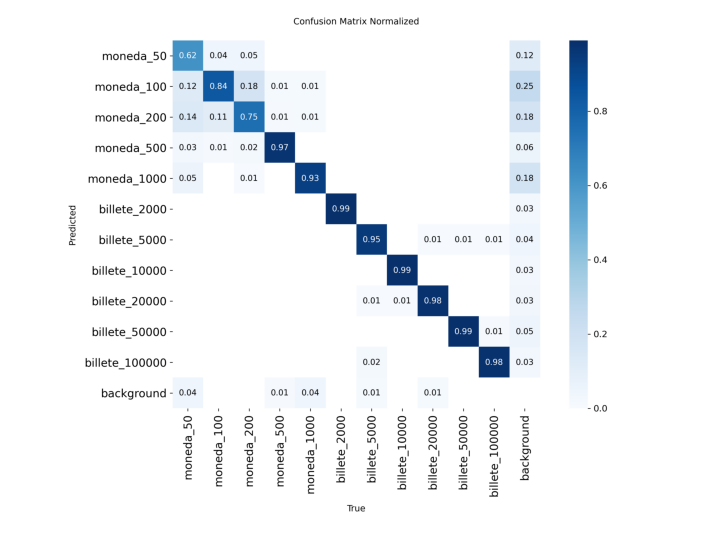

In [14]:
# Ultralytics guardó la matriz de confusión como imagen durante el entrenamiento (plots=True)
matriz = plt.imread(carpeta / "confusion_matrix_normalized.png")
plt.figure(figsize=(9, 8))
plt.imshow(matriz)
plt.axis("off")
plt.show()

## 8. Oclusión

Las fotos de prueba se separan en tres grupos según sus etiquetas: una sola pieza, varias separadas, y varias tocándose o tapándose (cuando dos cajas etiquetadas se cruzan). En cada grupo se mide en cuántas fotos acierta el conteo.

Un billete doblado, arrugado o superpuesto entra en "varias, tocándose" cuando su caja cruza la de otra pieza. En los billetes esa caja es el rectángulo que envuelve el contorno. Si está solo, aunque venga doblado, queda en "una sola".

La segunda tabla separa las fotos que solo tienen monedas, las que solo tienen billetes y las que mezclan los dos.

En `sint_test` la misma medida separa las escenas cuyas cajas se cruzan de las que quedan separadas.


### Cruce y grupo

Si dos cajas se cruzan, las piezas se tocan o se tapan. Con eso se arma el grupo de la foto, y aparte se anota si hay monedas, billetes o los dos.


In [15]:
# 1. Dos cajas se cruzan cuando se solapan en el eje x y en el eje y al mismo tiempo
def cajas_se_cruzan(texto):
    cajas = [caja[1:] for caja in cajas_xyxy(texto, 1000, 1000)]
    for i in range(len(cajas)):
        for j in range(i + 1, len(cajas)):
            a, b = cajas[i], cajas[j]
            if a[0] < b[2] and b[0] < a[2] and a[1] < b[3] and b[1] < a[3]:
                return True
    return False


# 2. Grupo de la foto según sus etiquetas
def grupo_oclusion(texto):
    piezas = len([linea for linea in texto.splitlines() if linea.strip()])
    if piezas <= 1:
        return "una sola"
    if cajas_se_cruzan(texto):
        return "varias, tocándose"
    return "varias, separadas"


# 3. Solo monedas, solo billetes, o las dos cosas
def tipo_escena(texto):
    ids = [int(float(linea.split()[0])) for linea in texto.splitlines() if linea.strip()]
    hay_moneda = any(clase <= 4 for clase in ids)
    hay_billete = any(clase >= 5 for clase in ids)
    if hay_moneda and hay_billete:
        return "monedas y billetes"
    if hay_billete:
        return "solo billetes"
    return "solo monedas"


### Tabla y fallos

El acierto de cada grupo, el acierto según haya monedas, billetes o los dos, y hasta tres fotos donde las piezas se tocan.


                   fotos acierto
grupo                           
una sola            1487   95.8%
varias, separadas     48   70.8%
varias, tocándose     44   59.1%
               fotos acierto
tipo                        
solo billetes   1163   98.1%
solo monedas     416   82.7%


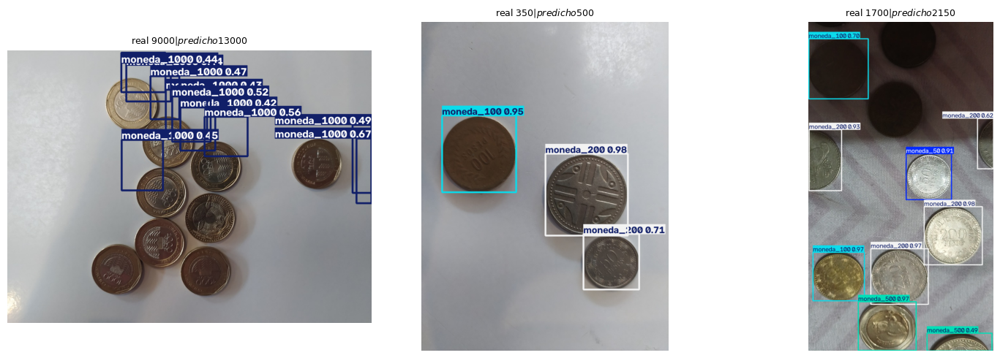

sint_test, por cruce de cajas
                          fotos acierto
separadas_o_superpuestas               
separadas                   150   61.3%
superpuestas                150   60.7%


In [16]:
# 4. Agregamos el grupo y el tipo, y medimos el acierto de cada uno
textos = [
    (test_labels / f"{Path(nombre).stem}.txt").read_text(encoding="utf-8")
    for nombre in tabla["imagen"]
]
tabla["grupo"] = [grupo_oclusion(texto) for texto in textos]
tabla["tipo"] = [tipo_escena(texto) for texto in textos]

def resumen_acierto(columna, frame=None):
    frame = tabla if frame is None else frame
    resumen = frame.groupby(columna).agg(fotos=("imagen", "count"), acierto=("coincide", "mean"))
    resumen["acierto"] = (resumen["acierto"] * 100).round(1).astype(str) + "%"
    return resumen

print(resumen_acierto("grupo"))
print(resumen_acierto("tipo"))

# 5. Mostramos hasta 3 fallos donde las piezas se tocan o se tapan
fallos_oclusion = tabla[(tabla["grupo"] == "varias, tocándose") & ~tabla["coincide"]].head(3)
if len(fallos_oclusion) > 0:
    fig, ejes = plt.subplots(1, len(fallos_oclusion), figsize=(5 * len(fallos_oclusion), 5))
    if len(fallos_oclusion) == 1:
        ejes = [ejes]
    for eje, (_, fila) in zip(ejes, fallos_oclusion.iterrows()):
        resultado = detector.predict(str(test_dir / fila["imagen"]), conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        eje.imshow(cv2.cvtColor(resultado.plot(), cv2.COLOR_BGR2RGB))
        eje.axis("off")
        eje.set_title(f"real ${fila['real']} | predicho ${fila['predicho']}", fontsize=9)
    fig.tight_layout()
    plt.show()

# 6. La misma tabla de oclusion sobre las escenas de prueba
sint_test_labels = ROOT / "data" / "monedas_billetes" / "labels" / "sint_test"
textos_sint = [
    (sint_test_labels / f"{Path(nombre).stem}.txt").read_text(encoding="utf-8")
    for nombre in tabla_sint["imagen"]
]
tabla_sint = tabla_sint.copy()
tabla_sint["grupo"] = [grupo_oclusion(texto) for texto in textos_sint]
tabla_sint["separadas_o_superpuestas"] = tabla_sint["grupo"].map({
    "varias, separadas": "separadas",
    "varias, tocándose": "superpuestas",
    "una sola": "una sola",
})
print("sint_test, por cruce de cajas")
print(resumen_acierto("separadas_o_superpuestas", tabla_sint))


## 9. Iluminación

Las mismas fotos se pasan con cuatro iluminaciones: más oscura, normal, con más luz y sobreexpuesta. `convertScaleAbs` multiplica cada píxel por `alpha` y le suma `beta`.

Monedas y billetes usan el mismo denominador que la sección 6: solo las fotos que de verdad traen ese tipo. También se mide `sint_test`.


Prueba real


     iluminación acierto monedas billetes
0         oscura   94.1%   82.9%    98.1%
1         normal   94.0%   82.9%    98.1%
2        más luz   88.4%   80.3%    91.6%
3  sobreexpuesta   46.7%   45.0%    47.4%
Escenas sintéticas de prueba


     iluminación acierto monedas billetes
0         oscura   56.3%   56.6%    77.9%
1         normal   61.0%   58.2%    82.4%
2        más luz   26.3%   44.0%    43.4%
3  sobreexpuesta    1.0%   13.2%     8.1%


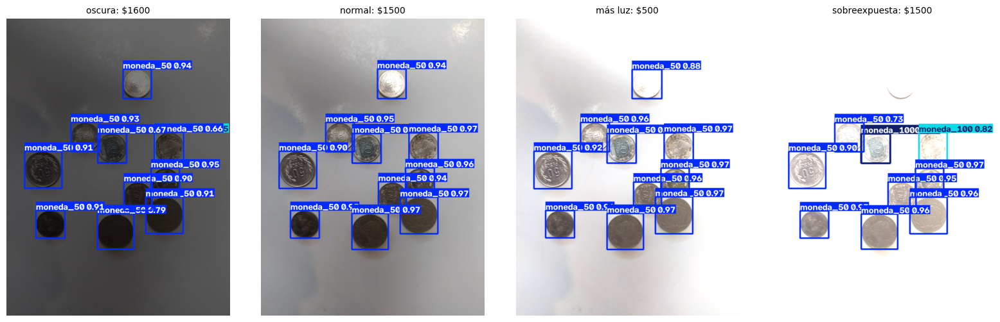

In [17]:
# 1. Iluminacion simulada. El acierto de monedas y de billetes usa solo las fotos que los tienen
condiciones = {
    "oscura": (0.5, 0),
    "normal": (1.0, 0),
    "más luz": (1.3, 40),
    "sobreexpuesta": (1.6, 90),
}

def evaluar_luz(filas_local, directorio):
    rutas = [directorio / fila["imagen"] for fila in filas_local]
    n_monedas = sum(fila["real_monedas"] > 0 for fila in filas_local)
    n_billetes = sum(fila["real_billetes"] > 0 for fila in filas_local)
    salida = []
    for condicion, (alpha, beta) in condiciones.items():
        aciertos = 0
        aciertos_monedas = 0
        aciertos_billetes = 0
        for inicio in range(0, len(rutas), 32):
            lote_rutas = rutas[inicio:inicio + 32]
            lote_filas = filas_local[inicio:inicio + 32]
            lote = [cv2.convertScaleAbs(cv2.imread(str(ruta)), alpha=alpha, beta=beta) for ruta in lote_rutas]
            predichos = detector.predict(
                lote, conf=CONF, imgsz=IMGSZ, batch=16, device=DEVICE, stream=True, verbose=False
            )
            for fila, resultado in zip(lote_filas, predichos):
                predicho = conteo_predicho(resultado)
                aciertos += predicho == fila["real_conteo"]
                if fila["real_monedas"] > 0:
                    aciertos_monedas += parte(predicho, "moneda_") == parte(fila["real_conteo"], "moneda_")
                if fila["real_billetes"] > 0:
                    aciertos_billetes += parte(predicho, "billete_") == parte(fila["real_conteo"], "billete_")
        salida.append({
            "iluminación": condicion,
            "acierto": f"{aciertos / len(filas_local):.1%}",
            "monedas": f"{aciertos_monedas / n_monedas:.1%}" if n_monedas else "n/a",
            "billetes": f"{aciertos_billetes / n_billetes:.1%}" if n_billetes else "n/a",
        })
    return pd.DataFrame(salida)

print("Prueba real")
filas_luz = evaluar_luz(filas, test_dir)
print(filas_luz)
print("Escenas sintéticas de prueba")
filas_luz_sint = evaluar_luz(filas_sint, ROOT / "data" / "monedas_billetes" / "images" / "sint_test")
print(filas_luz_sint)

fig, ejes = plt.subplots(1, len(condiciones), figsize=(16, 5))
for eje, (condicion, (alpha, beta)) in zip(ejes, condiciones.items()):
    imagen = cv2.convertScaleAbs(cv2.imread(str(imagen_demo)), alpha=alpha, beta=beta)
    resultado = detector.predict(imagen, conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    eje.imshow(cv2.cvtColor(resultado.plot(), cv2.COLOR_BGR2RGB))
    eje.axis("off")
    eje.set_title(f"{condicion}: ${total_pesos(conteo_predicho(resultado))}", fontsize=10)
fig.tight_layout()
plt.show()
plt.close(fig)


## 10. Entrenamiento con todas las fotos

Los hiperparámetros ya están elegidos. Se vuelve a entrenar desde `yolo26n.pt`, con la receta de B: SGD, `lr0=0.01`, `cls=1.0`, `cos_lr`, 50 épocas, tamaño 640, lote 16 y sin `copy_paste`.

Entran las fotos reales y las escenas sintéticas de entrenamiento, validación y prueba. Este modelo no se usa en las secciones 5 a 9. Como la validación también está dentro del entrenamiento, las fotos y los videos propios usan `last.pt`, no `best.pt`. El resultado queda en `monedas_final_sint`. El mAP de esta corrida no se cita como nota: la validación ya se vio durante el entrenamiento.


In [18]:
# 1. Fotos reales y escenas de todos los splits. Sin copy_paste
datos = ROOT / "data" / "monedas_billetes"
nombres = list(CLASS_VALUE)
yaml_final = RUN / "data_final_sint.yaml"
yaml_final.write_text(
    "path: " + datos.as_posix() + "\n"
    "train:\n"
    "  - images/train\n"
    "  - images/val\n"
    "  - images/test\n"
    "  - images/sint_train\n"
    "  - images/sint_val\n"
    "  - images/sint_test\n"
    "val: images/val\n"
    "nc: " + str(len(nombres)) + "\n"
    "names: [" + ", ".join("'" + nombre + "'" for nombre in nombres) + "]\n",
    encoding="utf-8",
)

pesos_final = RUN / "monedas_final_sint" / "weights" / "last.pt"
if pesos_final.exists():
    print("Se reutiliza", pesos_final)
else:
    modelo_final = YOLO(str(PRETRAINED))
    modelo_final.train(
        data=str(yaml_final),
        epochs=50,
        patience=50,
        batch=int(ganador["batch"]),
        imgsz=int(ganador["imgsz"]),
        cls=float(ganador["cls"]),
        lr0=float(ganador["lr0"]),
        optimizer="SGD",
        cos_lr=True,
        cache=True,
        seed=42,
        workers=2,
        device=DEVICE,
        project=str(RUN),
        name="monedas_final_sint",
        exist_ok=True,
        plots=False,
    )
detector_final = YOLO(str(pesos_final))
print("Entrenamiento final terminado. Pesos:", pesos_final)


Entrenamiento final terminado. Pesos: C:\Users\Usuario\Documents\ICESI\Maestria Inteligencia Artificial aplicada\SEMESTRE 2\Proyecto II\3\taller\modelo_extras\monedas_final_sint\weights\last.pt


## 11. Fotos propias

Ocho fotos nuestras, fuera de Roboflow. Se infieren con `last.pt` de la sección 10 y con el tamaño elegido en la sección 3b.

El conteo real se armó mirando cada foto. Los billetes de la 04 suman $367000, los de la 05 y la 06 $617000, los de la 07 $229000 y los de la 08 $319000. Las monedas de la 03 están encimadas: el conteo real incluye las que se alcanzan a ver.

Hay una sola figura por foto. La tabla compara el total real con el predicho.


foto_01_monedas_separadas.JPG
  real:     Se detectaron 1 moneda de 50, 2 monedas de 100, 3 monedas de 200, 2 monedas de 500 y 1 moneda de 1000. Total en escena: $2850
  predicho: Se detectaron 2 monedas de 100, 3 monedas de 200, 2 monedas de 500 y 1 moneda de 1000. Total en escena: $2800


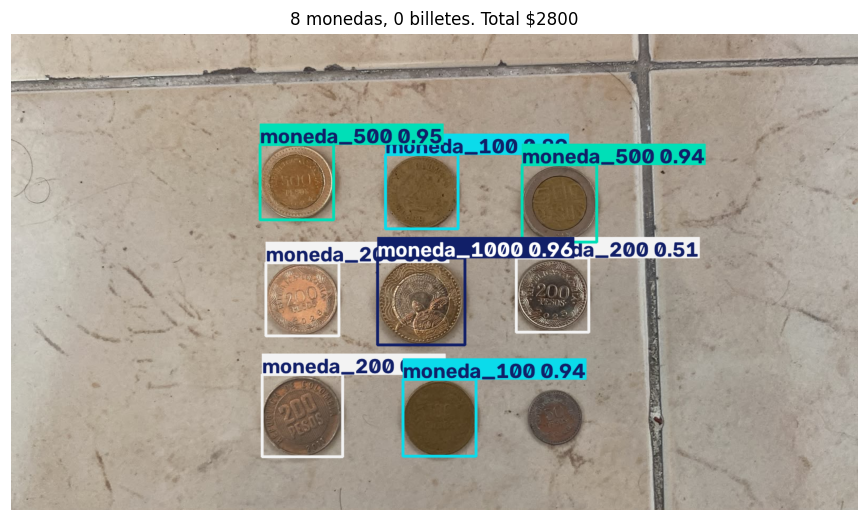

foto_02_monedas_con_contacto.JPG
  real:     Se detectaron 1 moneda de 50, 5 monedas de 100, 5 monedas de 200, 4 monedas de 500 y 1 moneda de 1000. Total en escena: $4550
  predicho: Se detectaron 1 moneda de 50, 6 monedas de 100, 5 monedas de 200, 2 monedas de 500 y 2 monedas de 1000. Total en escena: $4650


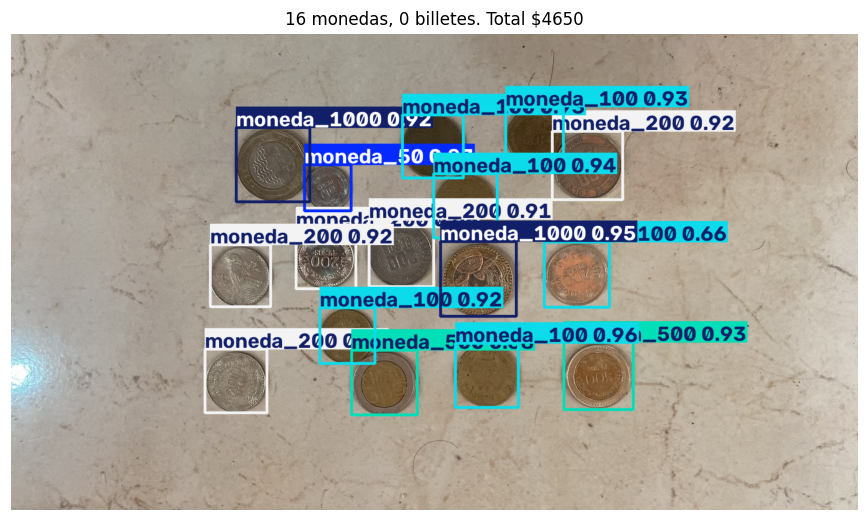

foto_03_monedas_superpuestas.JPG
  real:     Se detectaron 1 moneda de 50, 5 monedas de 100, 5 monedas de 200, 3 monedas de 500 y 1 moneda de 1000. Total en escena: $4050
  predicho: Se detectaron 1 moneda de 50, 4 monedas de 100, 7 monedas de 200, 3 monedas de 500 y 2 monedas de 1000. Total en escena: $5350


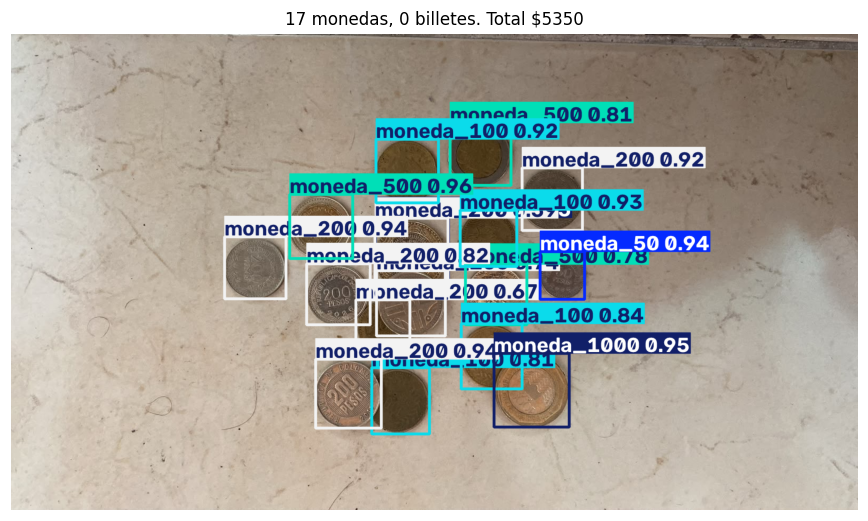

foto_04_billetes_separados.JPG
  real:     Se detectaron 1 billete de 2000, 1 billete de 5000, 3 billetes de 20000, 2 billetes de 50000 y 2 billetes de 100000. Total en escena: $367000
  predicho: Se detectaron 1 billete de 2000, 1 billete de 5000, 3 billetes de 20000, 2 billetes de 50000 y 2 billetes de 100000. Total en escena: $367000


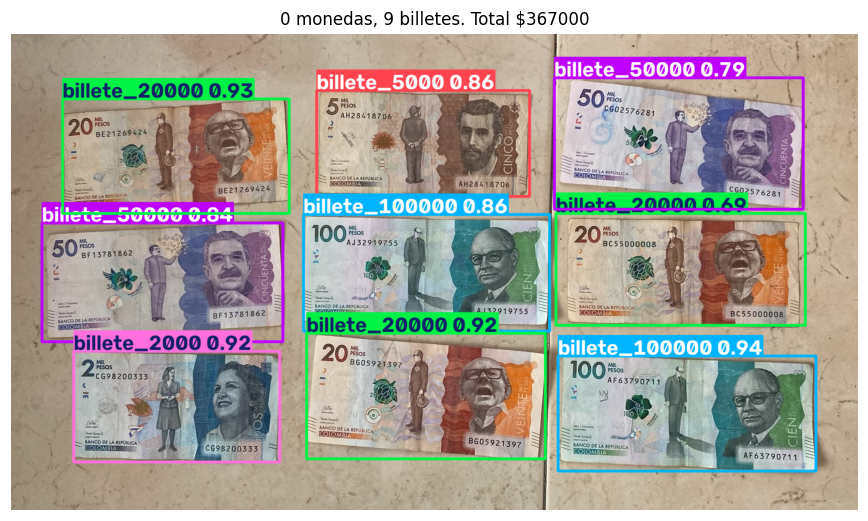

foto_05_billetes_superpuestos.JPG


  real:     Se detectaron 1 billete de 2000, 3 billetes de 5000, 2 billetes de 10000, 4 billetes de 20000, 4 billetes de 50000 y 3 billetes de 100000. Total en escena: $617000
  predicho: Se detectaron 2 billetes de 2000, 3 billetes de 5000, 3 billetes de 10000, 4 billetes de 20000, 4 billetes de 50000 y 3 billetes de 100000. Total en escena: $629000


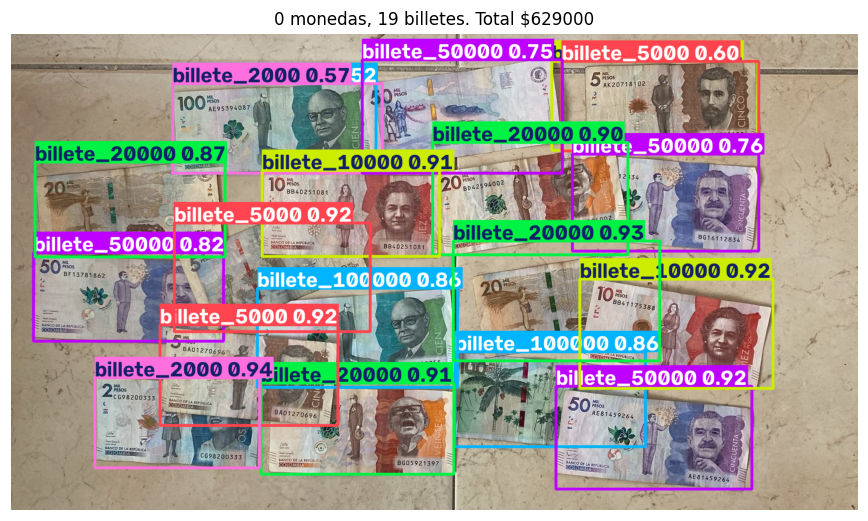

foto_06_billetes_en_posiciones_variadas.JPG
  real:     Se detectaron 1 billete de 2000, 3 billetes de 5000, 2 billetes de 10000, 4 billetes de 20000, 4 billetes de 50000 y 3 billetes de 100000. Total en escena: $617000
  predicho: Se detectaron 1 billete de 2000, 3 billetes de 5000, 1 billete de 10000, 4 billetes de 20000, 5 billetes de 50000 y 3 billetes de 100000. Total en escena: $657000


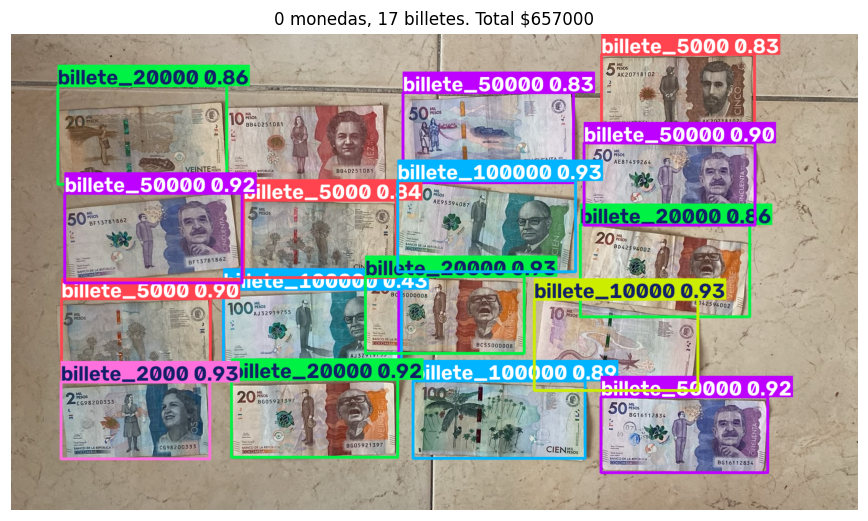

foto_07_monedas_y_billetes_organizados.JPG
  real:     Se detectaron 3 monedas de 100, 4 monedas de 200, 3 monedas de 500, 2 billetes de 2000, 1 billete de 5000, 1 billete de 10000, 3 billetes de 20000, 1 billete de 50000 y 1 billete de 100000. Total en escena: $231600
  predicho: Se detectaron 2 monedas de 100, 4 monedas de 200, 3 monedas de 500, 2 monedas de 1000, 2 billetes de 2000, 1 billete de 5000, 1 billete de 10000, 3 billetes de 20000, 1 billete de 50000 y 1 billete de 100000. Total en escena: $233500


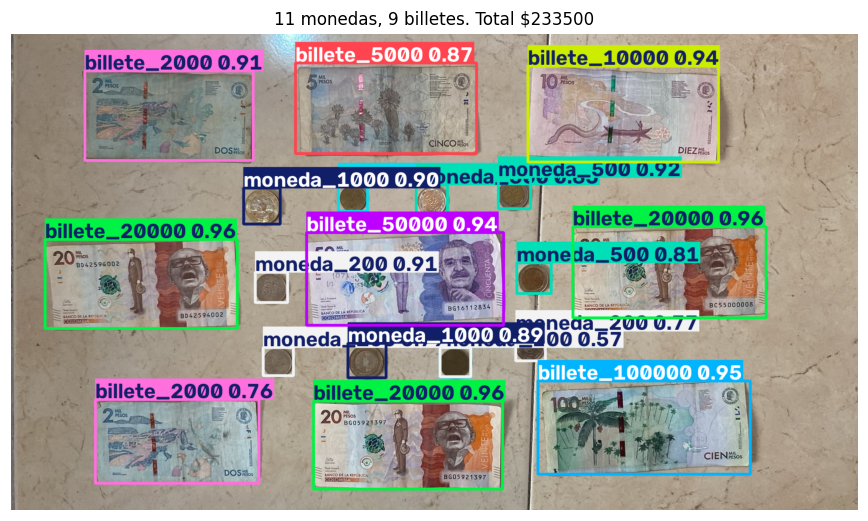

foto_08_monedas_y_billetes_con_superposicion.JPG
  real:     Se detectaron 2 monedas de 100, 5 monedas de 200, 3 monedas de 500, 1 moneda de 1000, 2 billetes de 2000, 1 billete de 5000, 2 billetes de 10000, 2 billetes de 20000, 1 billete de 50000 y 2 billetes de 100000. Total en escena: $322700
  predicho: Se detectaron 6 monedas de 100, 4 monedas de 200, 2 monedas de 500, 2 monedas de 1000, 2 billetes de 2000, 1 billete de 5000, 2 billetes de 10000, 2 billetes de 20000, 1 billete de 50000 y 2 billetes de 100000. Total en escena: $323400


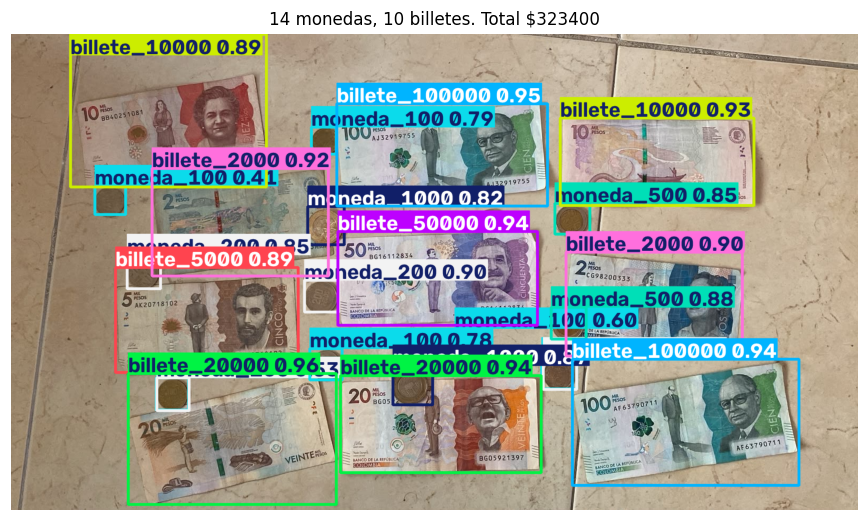

Fotos con el conteo exacto: 12.5%


,imagen,real,predicho,real_monedas,pred_monedas,real_billetes,pred_billetes,coincide
0,foto_01_monedas_separadas.JPG,2850,2800,2850,2800,0,0,False
1,foto_02_monedas_con_contacto.JPG,4550,4650,4550,4650,0,0,False
2,foto_03_monedas_superpuestas.JPG,4050,5350,4050,5350,0,0,False
3,foto_04_billetes_separados.JPG,367000,367000,0,0,367000,367000,True
4,foto_05_billetes_superpuestos.JPG,617000,629000,0,0,617000,629000,False
5,foto_06_billetes_en_posiciones_variadas.JPG,617000,657000,0,0,617000,657000,False
6,foto_07_monedas_y_billetes_organizados.JPG,231600,233500,2600,4500,229000,229000,False
7,foto_08_monedas_y_billetes_con_superposicion.JPG,322700,323400,3700,4400,319000,319000,False


In [19]:
# 1. Una figura por foto y la tabla real contra predicho
propias_dir = ROOT / "fotos_propias"
fotos = [propias_dir / nombre for nombre in REAL_PROPIAS]
faltan = [foto.name for foto in fotos if not foto.exists()]
if faltan:
    print("Faltan estas fotos en", propias_dir, ":", ", ".join(faltan))

filas_propias = []
for foto in fotos:
    if not foto.exists():
        continue
    resultado = detector_final.predict(str(foto), conf=CONF, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
    predicho = conteo_predicho(resultado)
    real = REAL_PROPIAS[foto.name]
    filas_propias.append({
        "imagen": foto.name,
        "real": total_pesos(real),
        "predicho": total_pesos(predicho),
        "real_monedas": total_pesos(parte(real, "moneda_")),
        "pred_monedas": total_pesos(parte(predicho, "moneda_")),
        "real_billetes": total_pesos(parte(real, "billete_")),
        "pred_billetes": total_pesos(parte(predicho, "billete_")),
        "coincide": real == predicho,
    })
    print(foto.name)
    print("  real:    ", texto_escena(real))
    print("  predicho:", texto_escena(predicho))
    plt.figure(figsize=(8, 5))
    plt.imshow(cv2.cvtColor(resultado.plot(), cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.title(titulo_corto(predicho), fontsize=11)
    plt.show()
    plt.close()

tabla_propias = pd.DataFrame(filas_propias)
print(f"Fotos con el conteo exacto: {tabla_propias['coincide'].mean():.1%}")
tabla_propias[["imagen", "real", "predicho", "real_monedas", "pred_monedas", "real_billetes", "pred_billetes", "coincide"]]


## 12. Videos propios

Tres videos nuestros, con el modelo de la sección 10. El número no es el de un solo frame: es la mediana de cada denominación en las últimas 15 frames. Debajo del video, una franja blanca lista las monedas, los billetes y el total, sin tapar la imagen.

El tamaño de inferencia es 832 o 1024, el más cercano al lado mayor del frame. El video guardado no pasa de 960 px en el lado mayor; la franja se suma debajo. El reproductor apunta al archivo, no lo embebe, para que esta libreta no pese cientos de megabytes. Los mp4 quedan en `modelo_extras/videos/`.


In [20]:
# 1. Mediana por clase en 15 frames, franja blanca debajo, video por debajo de 960 px, sin embeberlo
from IPython.display import Video, display

videos = [
    propias_dir / "video_01_monedas_quitar_y_agregar.MP4",
    propias_dir / "video_02_billetes_quitar_y_agregar.MP4",
    propias_dir / "video_03_monedas_y_billetes_quitar_y_agregar.MP4",
]
faltan_videos = [video.name for video in videos if not video.exists()]
if faltan_videos:
    print("Faltan estos videos en", propias_dir, ":", ", ".join(faltan_videos))
salida_videos = RUN / "videos"
salida_videos.mkdir(parents=True, exist_ok=True)


def imgsz_del_frame(ancho, alto):
    return 832 if max(ancho, alto) <= 928 else 1024


def tamano_salida(ancho, alto, tope=960):
    escala = min(1.0, tope / max(ancho, alto))
    return max(2, int(ancho * escala) // 2 * 2), max(2, int(alto * escala) // 2 * 2)


def conteo_mediana(ventana):
    recientes = ventana[-15:]
    estable = {nombre: 0 for nombre in CLASS_NAMES}
    for nombre in CLASS_NAMES:
        estable[nombre] = int(round(statistics.median([int(conteo[nombre]) for conteo in recientes])))
    return estable


def abrir_salida(destino, fps, ancho, alto):
    for codigo in ("avc1", "mp4v"):
        salida = cv2.VideoWriter(str(destino), cv2.VideoWriter_fourcc(*codigo), fps, (ancho, alto))
        if salida.isOpened():
            return salida
        salida.release()
    raise RuntimeError(f"No pude crear el video {destino.name}")


# Franja blanca debajo del frame. El alto es fijo para que todos los frames midan igual.
MARGEN_FRANJA = 18
ALTO_LINEA = 36
LINEAS_FRANJA = 3
ESCALA_TEXTO = 0.75
GROSOR_TEXTO = 2


def alto_franja():
    return MARGEN_FRANJA * 2 + ALTO_LINEA * LINEAS_FRANJA


def lineas_dinero(conteos):
    def frase(prefijo, etiqueta, vacio):
        partes = []
        for nombre in CLASS_NAMES:
            if not nombre.startswith(prefijo):
                continue
            cantidad = int(conteos.get(nombre, 0))
            if cantidad <= 0:
                continue
            partes.append(f"{cantidad} de {CLASS_VALUE[nombre]}")
        if not partes:
            return f"{etiqueta}: {vacio}."
        return f"{etiqueta}: " + ", ".join(partes) + "."

    return [
        frase("moneda_", "Monedas", "ninguna"),
        frase("billete_", "Billetes", "ninguno"),
        f"Total en escena: ${total_pesos(conteos)}",
    ]


def partir_texto(texto_linea, ancho_px):
    palabras = texto_linea.split()
    lineas = []
    actual = ""
    for palabra in palabras:
        candidato = palabra if not actual else f"{actual} {palabra}"
        ancho_texto = cv2.getTextSize(candidato, cv2.FONT_HERSHEY_SIMPLEX, ESCALA_TEXTO, GROSOR_TEXTO)[0][0]
        if ancho_texto <= ancho_px or not actual:
            actual = candidato
        else:
            lineas.append(actual)
            actual = palabra
    if actual:
        lineas.append(actual)
    return lineas


def agregar_franja(imagen, conteos):
    alto, ancho = imagen.shape[:2]
    lineas = []
    for frase in lineas_dinero(conteos):
        lineas.extend(partir_texto(frase, max(40, ancho - 24)))
    lineas = lineas[:LINEAS_FRANJA]
    lienzo = cv2.copyMakeBorder(imagen, 0, alto_franja(), 0, 0, cv2.BORDER_CONSTANT, value=(255, 255, 255))
    y = alto + MARGEN_FRANJA + 24
    for linea in lineas:
        cv2.putText(
            lienzo, linea, (12, y), cv2.FONT_HERSHEY_SIMPLEX, ESCALA_TEXTO, (0, 0, 0), GROSOR_TEXTO, cv2.LINE_AA,
        )
        y += ALTO_LINEA
    return lienzo


def reproducir(video):
    captura = cv2.VideoCapture(str(video))
    if not captura.isOpened():
        print("No se pudo abrir", video.name)
        return
    fps = captura.get(cv2.CAP_PROP_FPS)
    if not fps or fps < 1:
        fps = 20
    ancho = int(captura.get(cv2.CAP_PROP_FRAME_WIDTH))
    alto = int(captura.get(cv2.CAP_PROP_FRAME_HEIGHT))
    tam = imgsz_del_frame(ancho, alto)
    salida_w, salida_h = tamano_salida(ancho, alto)
    destino = salida_videos / f"{video.stem}.mp4"
    salida = abrir_salida(destino, fps, salida_w, salida_h + alto_franja())
    ventana = []
    while True:
        ok, frame = captura.read()
        if not ok:
            break
        resultado = detector_final.predict(frame, conf=CONF, imgsz=tam, device=DEVICE, verbose=False)[0]
        ventana.append(conteo_predicho(resultado))
        imagen = resultado.plot()
        if imagen.shape[1] != salida_w or imagen.shape[0] != salida_h:
            imagen = cv2.resize(imagen, (salida_w, salida_h))
        imagen = agregar_franja(imagen, conteo_mediana(ventana))
        salida.write(imagen)
    captura.release()
    salida.release()
    print(video.name, "->", destino.relative_to(ROOT).as_posix(), "| imgsz", tam)
    display(Video(destino.relative_to(ROOT).as_posix(), embed=False, width=640))


for video in videos:
    if video.exists():
        reproducir(video)


video_01_monedas_quitar_y_agregar.MP4 -> modelo_extras/videos/video_01_monedas_quitar_y_agregar.mp4 | imgsz 1024


video_02_billetes_quitar_y_agregar.MP4 -> modelo_extras/videos/video_02_billetes_quitar_y_agregar.mp4 | imgsz 832


video_03_monedas_y_billetes_quitar_y_agregar.MP4 -> modelo_extras/videos/video_03_monedas_y_billetes_quitar_y_agregar.mp4 | imgsz 832


## 13. Conclusiones

El modelo encuentra cada pieza, lee su denominación y suma el dinero de la escena. En una foto que no vio durante el entrenamiento la salida es la del enunciado: "Se detectaron 3 monedas de 100 y 1 de 500. Total en escena: $800".

La receta salió de la validación, no de la prueba. Entre las cuatro combinaciones de tasa inicial y peso de clase ganó `lr0=0.01` y `cls=1.0`, con SGD, lote 16, tamaño 640 y 50 épocas, partiendo de YOLO26 nano. El mejor mAP50 de esa receta, ya con escenas sintéticas, es 0.937 en la época 38. Al final la pérdida de clase queda en 0.441 en entrenamiento y 0.623 en validación. La red localiza la pieza. Lo que no termina de separar son denominaciones parecidas, y alargar el entrenamiento no cierra esa diferencia.

En la prueba real los falsos positivos y los falsos negativos son casi todos de monedas. Sobran detecciones de 200 (40) y de 100 (21). Faltan monedas de 50 (27). En billetes el error es menor: el falso positivo que más se repite es el de 100000 (4) y el falso negativo, el de 2000 (7). Un falso positivo mete en la suma un valor que no está. Un falso negativo deja fuera uno que sí está. Por eso un billete mal contado mueve el total mucho más que una moneda.

La oclusión baja el conteo. Una sola pieza acierta el 95.8 %. Varias separadas bajan a 70.8 %, y si se tocan, a 59.1 %. Casi todo Roboflow es una pieza por foto, así que ese 95.8 % no describe una mesa con varias. En las 300 escenas de prueba, separadas y superpuestas quedan parejas (61.3 % y 60.7 %): el modelo ya ve varias piezas juntas, y lo que sigue fallando es contar bien cuando unas tapan a otras.

La luz hace un daño del mismo tipo. Con luz oscura o normal el acierto se queda cerca del 94 %. Con más luz baja a 88.4 %, y si la foto queda sobreexpuesta, a 46.7 %. El brillo fuerte borra el relieve de la moneda y el grabado del billete, que es lo que distingue una denominación de otra.

En las ocho fotos nuestras el total cierra exacto solo en los billetes separados ($367000). En las demás el modelo se acerca: suele sobrar o faltar una moneda, o un billete cuando están encimados. En las dos fotos que mezclan monedas y billetes, los billetes sí cierran exactos.

El conteo también corre en este computador, sin la nube. `inferir.py` carga los pesos de `pesos/` y cuenta en CPU o en GPU. En video la suma no sale de un frame suelto: es la mediana de cada denominación en 15 frames, para que el número no salte cuando la confianza oscila.
